In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_bgr = cv2.imread('PDI P4.jpg')
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
filas, columnas, _ = img_rgb.shape
print("Dimensiones:", filas, "x", columnas)

Dimensiones: 447 x 447


**Parte 1** Ejercicio 1


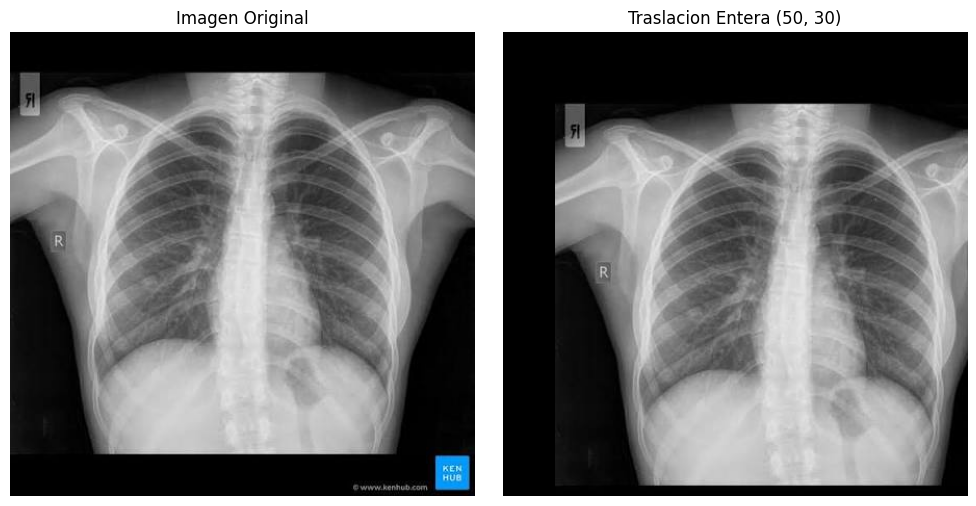

In [2]:
# Traslacion entera de (50, 30) pixeles
M_entera = np.float32([[1, 0, 50], [0, 1, 30]])
img_tras_entera = cv2.warpAffine(img_rgb, M_entera, (columnas, filas))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_rgb)
axes[0].set_title("Imagen Original")
axes[0].axis("off")

axes[1].imshow(img_tras_entera)
axes[1].set_title("Traslacion Entera (50, 30)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Ejercicio 2


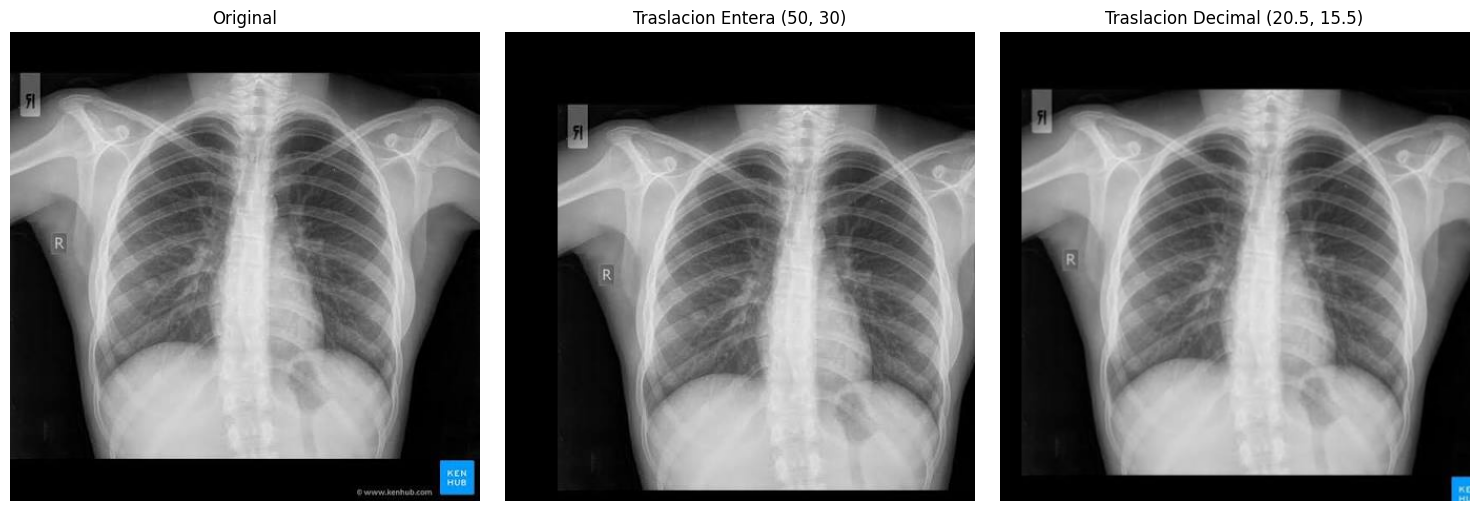

In [3]:
# Traslacion fraccional de (20.5, 15.5) pixeles
M_decimal = np.float32([[1, 0, 20.5], [0, 1, 15.5]])
img_tras_decimal = cv2.warpAffine(img_rgb, M_decimal, (columnas, filas))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_rgb)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(img_tras_entera)
axes[1].set_title("Traslacion Entera (50, 30)")
axes[1].axis("off")

axes[2].imshow(img_tras_decimal)
axes[2].set_title("Traslacion Decimal (20.5, 15.5)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

Ejercicio 3

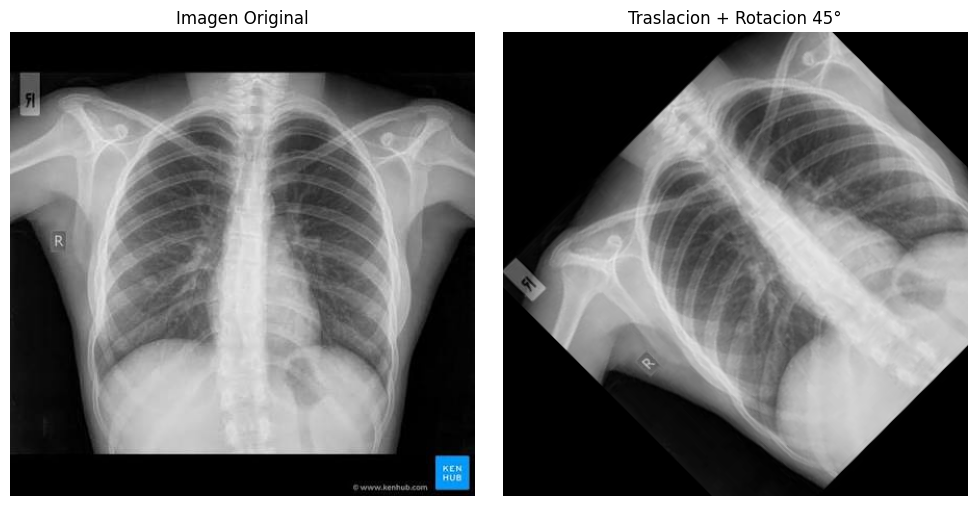

In [4]:
# Primero trasladamos y luego rotamos 45 grados alrededor del centro
centro = (columnas / 2, filas / 2)
M_rot = cv2.getRotationMatrix2D(centro, 45, 1.0)
img_tras_rot = cv2.warpAffine(img_tras_entera, M_rot, (columnas, filas))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_rgb)
axes[0].set_title("Imagen Original")
axes[0].axis("off")

axes[1].imshow(img_tras_rot)
axes[1].set_title("Traslacion + Rotacion 45°")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Ejercicio 4

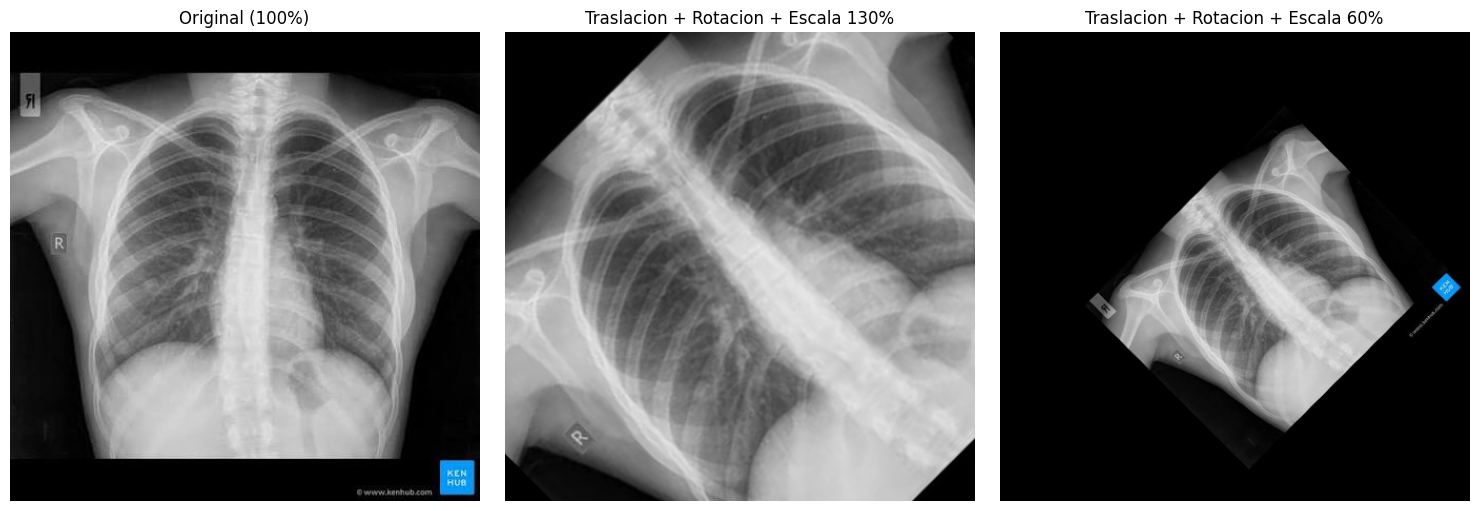

In [5]:
# Combinar traslacion, rotacion de 45 grados y escala mayor (130%) y menor (60%)
M_mayor = cv2.getRotationMatrix2D(centro, 45, 1.3)
M_mayor[0, 2] += 30
M_mayor[1, 2] += 20
img_combinada_mayor = cv2.warpAffine(img_rgb, M_mayor, (columnas, filas))

M_menor = cv2.getRotationMatrix2D(centro, 45, 0.6)
M_menor[0, 2] += 30
M_menor[1, 2] += 20
img_combinada_menor = cv2.warpAffine(img_rgb, M_menor, (columnas, filas))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_rgb)
axes[0].set_title("Original (100%)")
axes[0].axis("off")

axes[1].imshow(img_combinada_mayor)
axes[1].set_title("Traslacion + Rotacion + Escala 130%")
axes[1].axis("off")

axes[2].imshow(img_combinada_menor)
axes[2].set_title("Traslacion + Rotacion + Escala 60%")
axes[2].axis("off")

plt.tight_layout()
plt.show()

Ejercicio 5

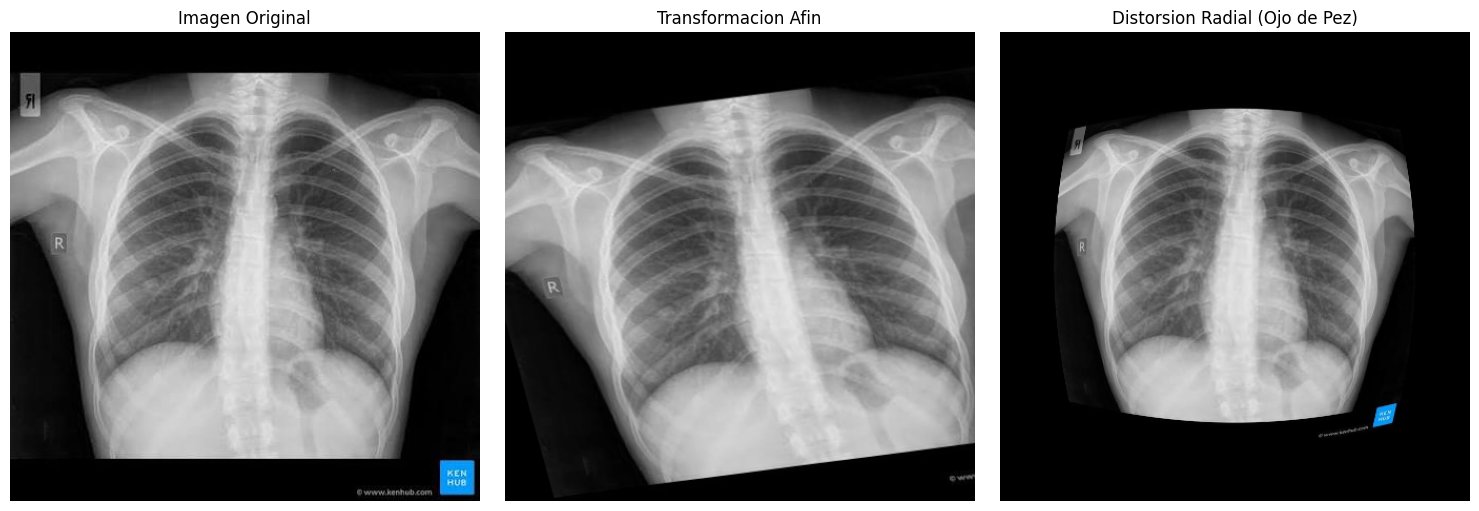

In [6]:
# Transformacion afin con puntos de referencia (OpenCV usa 3 puntos base para afin)
pts1 = np.float32([[50, 50], [columnas - 50, 50], [50, filas - 50]])
pts2 = np.float32([[10, 100], [columnas - 50, 50], [100, filas - 20]])
M_afin = cv2.getAffineTransform(pts1, pts2)
img_afin = cv2.warpAffine(img_rgb, M_afin, (columnas, filas))

# Distorsion radial (efecto ojo de pez)
x, y = np.meshgrid(np.linspace(-1, 1, columnas), np.linspace(-1, 1, filas))
r = np.sqrt(x**2 + y**2)
k_distorsion = 0.5
x_dist = x * (1 + k_distorsion * r**2)
y_dist = y * (1 + k_distorsion * r**2)

map_x = ((x_dist + 1) * columnas / 2).astype(np.float32)
map_y = ((y_dist + 1) * filas / 2).astype(np.float32)
img_radial = cv2.remap(img_rgb, map_x, map_y, interpolation=cv2.INTER_LINEAR)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_rgb)
axes[0].set_title("Imagen Original")
axes[0].axis("off")

axes[1].imshow(img_afin)
axes[1].set_title("Transformacion Afin")
axes[1].axis("off")

axes[2].imshow(img_radial)
axes[2].set_title("Distorsion Radial (Ojo de Pez)")
axes[2].axis("off")

plt.tight_layout()
plt.show()